# Лабораторная 4. Временные ряды. Модели AR MA.
**Выполнила:** Окулова Александра ИТ-14

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import requests

from io import BytesIO
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

### Упражнения

    Загрузите два временных ряда arma_ts1 и arma_ts2, выполнив код ниже.


In [2]:
# Load the first time series
response = requests.get("https://zenodo.org/records/10951538/files/arma_ts3.npz?download=1")
response.raise_for_status()
arma_ts1 = np.load(BytesIO(response.content))['signal']
print(len(arma_ts1))

# Load the second time series
response = requests.get("https://zenodo.org/records/10951538/files/arma_ts4.npz?download=1")
response.raise_for_status()
arma_ts2 = np.load(BytesIO(response.content))['signal']
print(len(arma_ts2))

479
1000


### Для каждого временного ряда:

    1. Разделите временной ряд на обучающий и тестовый.
        Используйте последние 30 значений в качестве тестовых для первого временного ряда.
        Используйте последние 100 значений в качестве тестовых для второго временного ряда.
    2. Сделайте временной ряд стационарным.
    3. Определите порядок модели AR.
    4. Вычислите прогноз тестовых данных с помощью модели AR(p).
    5. Определите порядок модели MA.
    6. Вычислите прогноз тестовых данных с помощью модели MA(q).


In [3]:
#1. Разделение на обучающие и тестовые данные
train1 = arma_ts1[:-30]
test1 = arma_ts1[-30:]
train2 = arma_ts2[:-100]
test2 = arma_ts2[-100:]

time1 = np.arange(len(arma_ts1))
time2 = np.arange(len(arma_ts2))

print("Временной ряд 1")
print("Обучающая выборка:", len(train1))
print("Тестовая выборка:", len(test1))
print("\nВременной ряд 2")
print("Обучающая выборка:", len(train2))
print("Тестовая выборка:", len(test2))


Временной ряд 1
Обучающая выборка: 449
Тестовая выборка: 30

Временной ряд 2
Обучающая выборка: 900
Тестовая выборка: 100


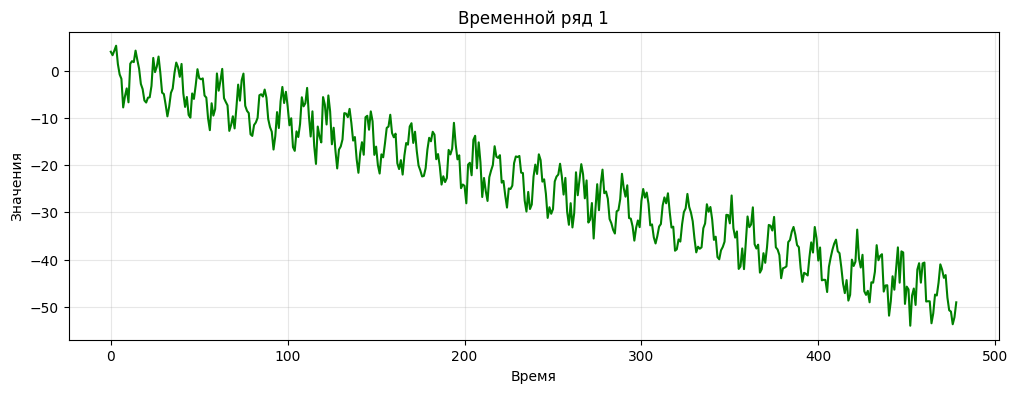

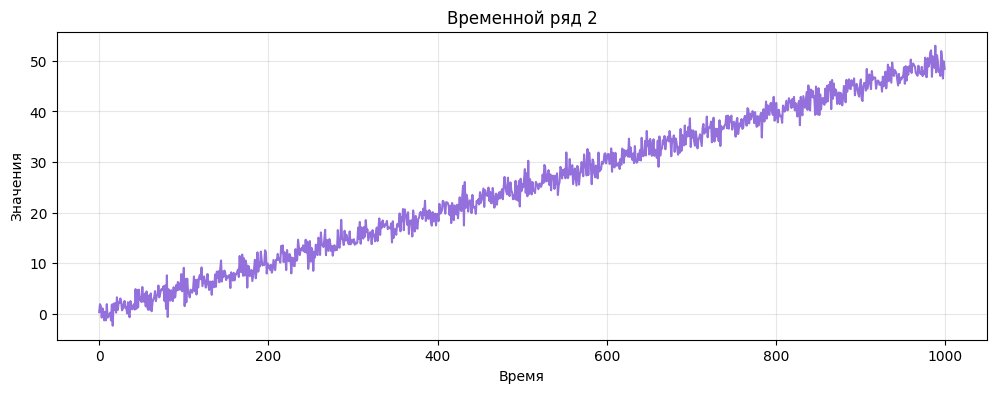

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(time1, arma_ts1, color="green")
plt.title("Временной ряд 1")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(time2, arma_ts2, color="mediumpurple")
plt.title("Временной ряд 2")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.grid(alpha=0.3)
plt.show()

In [5]:
#Определение периода сезонности первого ряда
t1 = np.arange(len(train1))
trend1 = np.polyval(np.polyfit(t1, train1, 1), t1)
detrended1 = train1 - trend1

spectrum = np.abs(np.fft.rfft(detrended1))
frequencies = np.fft.rfftfreq(len(detrended1))
peak = np.argmax(spectrum[1:]) + 1
period1 = int(round(1 / frequencies[peak]))

print("Период сезонности:", period1)

Период сезонности: 12


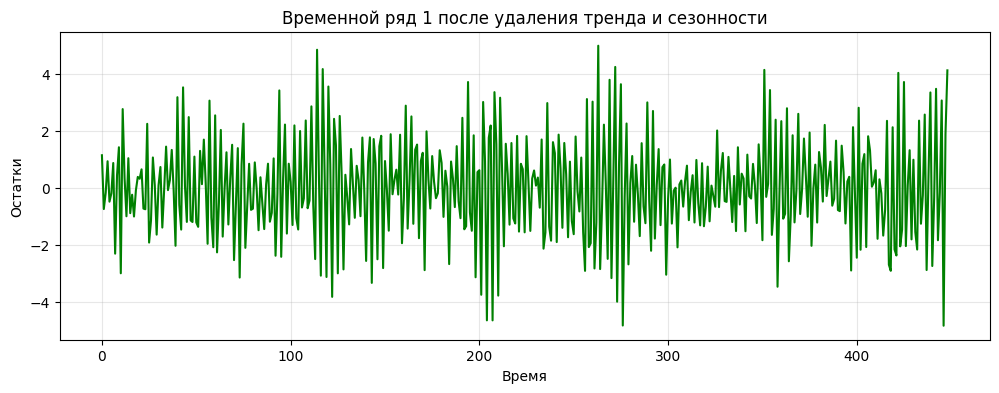

In [6]:
#Приведение первого ряда к стационарности
tes1 = ExponentialSmoothing(
    train1,
    trend="add",
    seasonal="add",
    seasonal_periods=period1,
    initialization_method="estimated"
).fit(smoothing_level=0.01)

#Остатки после удаления тренда и сезонности
resid1 = train1 - tes1.fittedvalues

#График остатков
plt.figure(figsize=(12, 4))
plt.plot(time1[:len(train1)], resid1, color="green")
plt.title("Временной ряд 1 после удаления тренда и сезонности")
plt.xlabel("Время")
plt.ylabel("Остатки")
plt.grid(alpha=0.3)
plt.show()

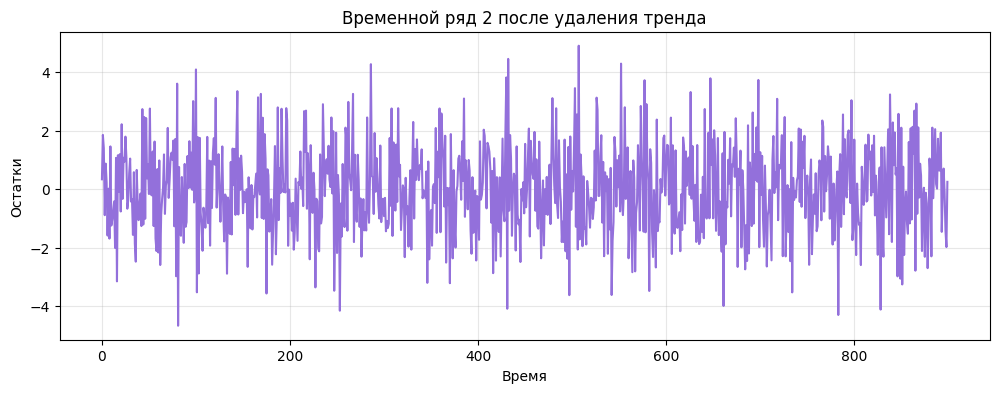

In [7]:
#Приведение второго ряда к стационарности
t2 = np.arange(len(train2))
coefficients2 = np.polyfit(t2, train2, 1)
trend2 = np.polyval(coefficients2, t2)

#Остатки после удаления тренда
resid2 = train2 - trend2

#График остатков
plt.figure(figsize=(12, 4))
plt.plot(time2[:len(train2)], resid2, color="mediumpurple")
plt.title("Временной ряд 2 после удаления тренда")
plt.xlabel("Время")
plt.ylabel("Остатки")
plt.grid(alpha=0.3)
plt.show()

In [8]:
#Проверим стационарность
#Сводная статистика по фрагментам
chunks1 = np.array_split(resid1, 10)
chunks2 = np.array_split(resid2, 10)

print("Сводная статистика по фрагментам")
print("Преобразованный ряд 1")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))
print("-" * 35)

for i, chunk1 in enumerate(chunks1, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(i, np.mean(chunk1), np.var(chunk1)))

print("\nПреобразованный ряд 2")
print("{}\t | {}\t\t | {}".format("Chunk", "Mean", "Variance"))
print("-" * 35)

for i, chunk2 in enumerate(chunks2, 1):
    print("{:2}\t | {:.5}\t | {:.5}".format(i, np.mean(chunk2), np.var(chunk2)))


Сводная статистика по фрагментам
Преобразованный ряд 1
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | 0.047273	 | 1.8522
 2	 | -0.16591	 | 2.2332
 3	 | 0.11685	 | 4.3138
 4	 | 0.15684	 | 2.3877
 5	 | -0.067861	 | 4.2583
 6	 | -0.0030506	 | 3.7019
 7	 | -0.21207	 | 3.3902
 8	 | 0.031637	 | 1.8942
 9	 | 0.14363	 | 2.2123
10	 | -0.048316	 | 4.9232

Преобразованный ряд 2
Chunk	 | Mean		 | Variance
-----------------------------------
 1	 | -0.035953	 | 2.1778
 2	 | 0.043188	 | 2.2724
 3	 | 0.03574	 | 2.4932
 4	 | -0.036981	 | 1.7888
 5	 | -0.044671	 | 2.3793
 6	 | 0.064538	 | 2.3484
 7	 | 0.025959	 | 2.555
 8	 | -0.065442	 | 2.5462
 9	 | -0.032434	 | 2.0543
10	 | 0.046055	 | 2.5676


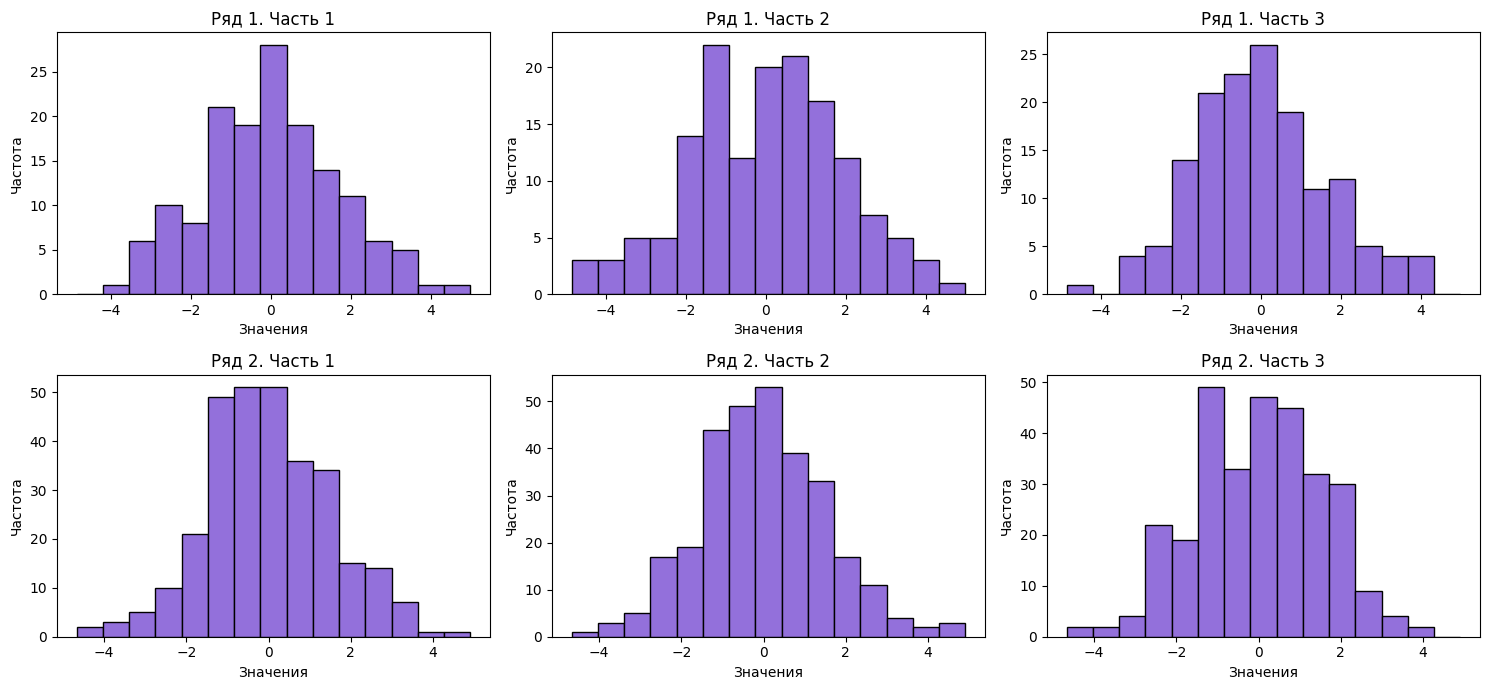

In [9]:
#Гистограммы
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

parts1 = np.array_split(resid1, 3)
parts2 = np.array_split(resid2, 3)
bins1 = np.histogram_bin_edges(resid1, bins=15)
bins2 = np.histogram_bin_edges(resid2, bins=15)

for i in range(3):
    axes[0, i].hist(parts1[i], bins=bins1, color="mediumpurple", edgecolor="black")
    axes[0, i].set_title(f"Ряд 1. Часть {i + 1}")
    axes[0, i].set_xlabel("Значения")
    axes[0, i].set_ylabel("Частота")
    axes[1, i].hist(parts2[i], bins=bins2, color="mediumpurple", edgecolor="black")
    axes[1, i].set_title(f"Ряд 2. Часть {i + 1}")
    axes[1, i].set_xlabel("Значения")
    axes[1, i].set_ylabel("Частота")

plt.tight_layout()
plt.show()

In [10]:
#Тест ADF для первого ряда
adf1, pvalue1, _, _, critical_values1, _ = adfuller(resid1, result_object=False)

print("Тест Дики-Фуллера")
print("Преобразованный временной ряд 1")
print(f"ADF: {adf1:.3f}")
print(f"p-value: {pvalue1:.6e}")
print("Критические значения:", critical_values1)

# Тест ADF для второго ряда
adf2, pvalue2, _, _, critical_values2, _ = adfuller(resid2, result_object=False)

print("\nПреобразованный временной ряд 2")
print(f"ADF: {adf2:.3f}")
print(f"p-value: {pvalue2:.6e}")
print("Критические значения:", critical_values2)


Тест Дики-Фуллера
Преобразованный временной ряд 1
ADF: -10.786
p-value: 2.192287e-19
Критические значения: {'1%': np.float64(-3.4450973903602367), '5%': np.float64(-2.868042229965336), '10%': np.float64(-2.570233448893)}

Преобразованный временной ряд 2
ADF: -17.224
p-value: 6.256000e-30
Критические значения: {'1%': np.float64(-3.437819842246547), '5%': np.float64(-2.8648374649929753), '10%': np.float64(-2.5685258078777093)}



Для первого временного ряда с помощью преобразования Фурье сезонный период = 12. Тренд и сезонность удалены методом тройного экспоненциального сглаживания.

Для второго временного ряда выполнено удаление линейного тренда.

После преобразований средние значения обоих рядов по фрагментам колеблются около нуля, а дисперсии не имеют выраженной тенденции к изменению.

По результатам теста Дики - Фуллера оба значения меньше уровня значимости 0.05.

Таким образом, полученные результаты свидетельствуют в пользу стационарности преобразованных рядов, что позволяет использовать их для построения моделей AR и MA.

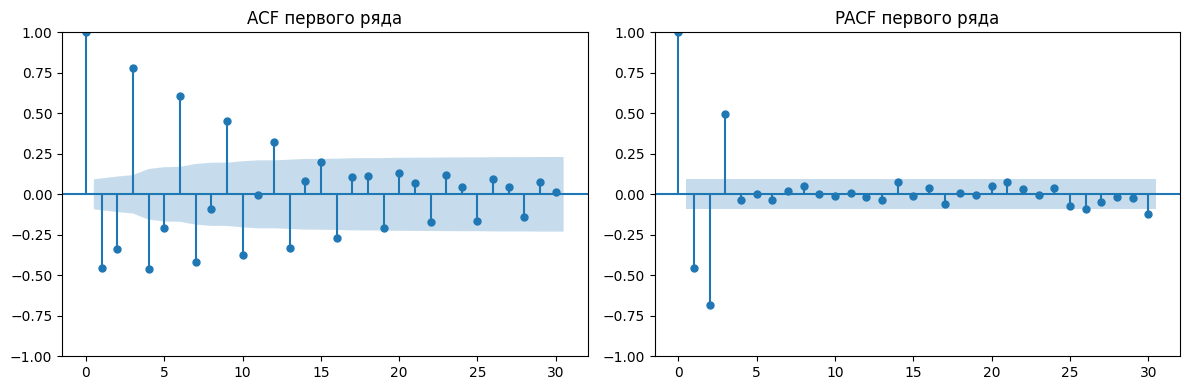

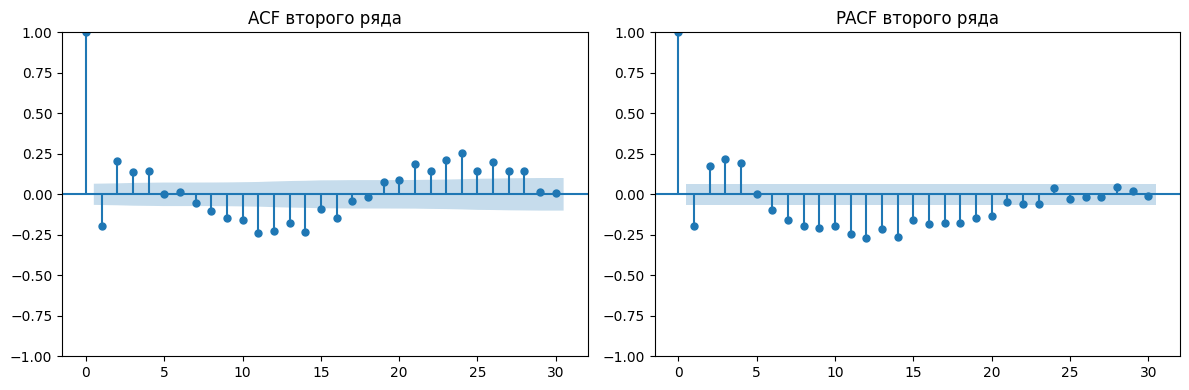

In [11]:
#Определим порядки моделей
#ACF и PACF первого ряда
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(resid1, lags=30, ax=axes[0],
         title="ACF первого ряда")

plot_pacf(resid1, lags=30, ax=axes[1],
          title="PACF первого ряда")

plt.tight_layout()
plt.show()

#ACF и PACF второго ряда
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(resid2, lags=30, ax=axes[0],
         title="ACF второго ряда")

plot_pacf(resid2, lags=30, ax=axes[1],
          title="PACF второго ряда")

plt.tight_layout()
plt.show()

### Определение порядков моделей AR и MA

**Первый временной ряд**

На графике PACF наблюдаются значимые пики на первых трёх лагах, после чего частичная автокорреляция резко уменьшается. Поэтому выбрана модель AR(3).

На графике ACF наблюдаются затухающие колебания. Последний выраженный значимый пик находится на лаге 16. Для построения прогноза выбрана модель MA(16).

**Второй временной ряд**

На графике PACF значимые значения наблюдаются вплоть до лага 20, после чего частичная автокорреляция уменьшается. Выбрана модель AR(20).

На графике ACF наблюдаются колебания автокорреляции, значимые пики сохраняются до лага 28. Выбрана модель MA(28).

Поскольку для некоторых графиков ACF и PACF отсутствует чёткая отсечка, выбранные порядки моделей рассматриваются как кандидаты, определённые по визуальному анализу значимых лагов.

In [12]:
#Прогноз первого ряда с помощью AR(3)
model_ar1 = ARIMA(resid1, order=(3, 0, 0))
model_fit_ar1 = model_ar1.fit()

#Прогноз остатков
resid_preds_ar1 = model_fit_ar1.forecast(steps=len(test1))

#Возвращаем тренд и сезонность
tes_pred = tes1.forecast(len(test1))
final_preds_ar1 = tes_pred + resid_preds_ar1

print("MSE AR(3):", mean_squared_error(test1, final_preds_ar1))

MSE AR(3): 2.1681788697765105


In [13]:
#Прогноз второго ряда с помощью AR(20)
model_ar2 = ARIMA(resid2, order=(20, 0, 0))
model_fit_ar2 = model_ar2.fit()

resid_preds_ar2 = model_fit_ar2.forecast(steps=len(test2))

trend_pred2 = np.polyval(coefficients2, time2[len(train2):])
final_preds_ar2 = trend_pred2 + resid_preds_ar2

print("MSE AR(20):", mean_squared_error(test2, final_preds_ar2))

MSE AR(20): 1.7325049643490806


In [14]:
#Прогноз первого ряда с помощью MA(16)
model_ma1 = ARIMA(resid1, order=(0, 0, 16))
model_fit_ma1 = model_ma1.fit()

resid_preds_ma1 = model_fit_ma1.forecast(steps=len(test1))

final_preds_ma1 = tes_pred + resid_preds_ma1

print("MSE MA(16):", mean_squared_error(test1, final_preds_ma1))


MSE MA(16): 1.5471940667838988


In [15]:
#Прогноз второго ряда с помощью MA(28)
model_ma2 = ARIMA(resid2, order=(0, 0, 28))
model_fit_ma2 = model_ma2.fit()

resid_preds_ma2 = model_fit_ma2.forecast(steps=len(test2))

final_preds_ma2 = trend_pred2 + resid_preds_ma2

print("MSE MA(28):", mean_squared_error(test2, final_preds_ma2))


MSE MA(28): 2.0889609126935995


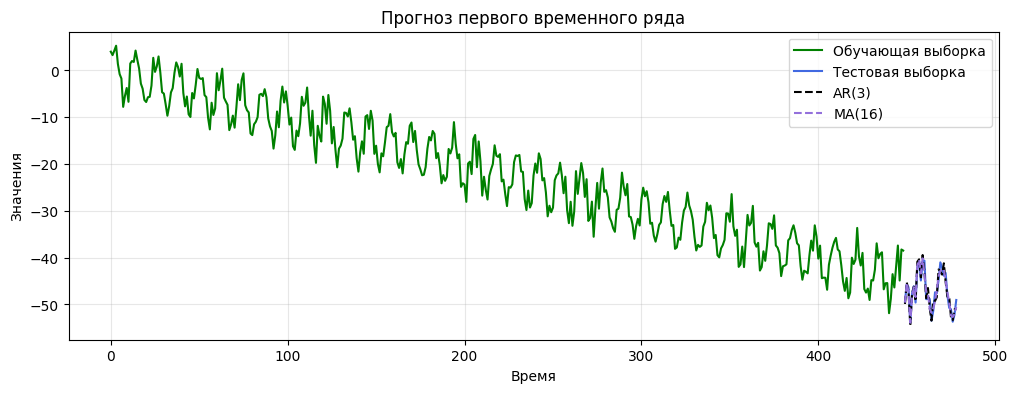

In [20]:
plt.figure(figsize=(12, 4))
plt.plot(time1[:len(train1)], train1,
         color="green", label="Обучающая выборка")

plt.plot(time1[len(train1):], test1,
         color="royalblue", label="Тестовая выборка")

plt.plot(time1[len(train1):], final_preds_ar1,
         color="black", linestyle="--", label="AR(3)")

plt.plot(time1[len(train1):], final_preds_ma1,
         color="mediumpurple", linestyle="--", label="MA(16)")

plt.title("Прогноз первого временного ряда")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

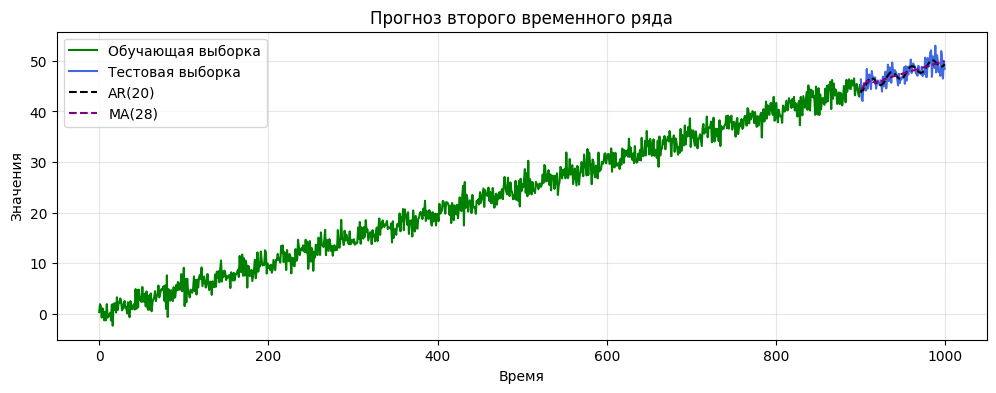

In [19]:
plt.figure(figsize=(12, 4))
plt.plot(time2[:len(train2)], train2,
         color="green", label="Обучающая выборка")

plt.plot(time2[len(train2):], test2,
         color="royalblue", label="Тестовая выборка")

plt.plot(time2[len(train2):], final_preds_ar2,
         color="black", linestyle="--", label="AR(20)")

plt.plot(time2[len(train2):], final_preds_ma2,
         color="purple", linestyle="--", label="MA(28)")

plt.title("Прогноз второго временного ряда")
plt.xlabel("Время")
plt.ylabel("Значения")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Вывод

В ходе лабораторной работы были исследованы модели авторегрессии (AR) и скользящего среднего (MA) для прогнозирования двух временных рядов.

Первоначально ряды были разделены на обучающие и тестовые выборки. Для первого ряда удалены тренд и сезонность методом тройного экспоненциального сглаживания, для второго линейный тренд. С помощью сводной статистики, гистограмм и теста Дики-Фуллера получены результаты, свидетельствующие в пользу стационарности преобразованных рядов.

На основании анализа графиков ACF и PACF определены порядки моделей AR и MA.

Для первого временного ряда получены следующие значения среднеквадратичной ошибки:

- AR(3): MSE = 2.168;
- MA(16): MSE = 1.547.

Наиболее точный прогноз первого ряда получен с помощью модели MA(16).

Для второго временного ряда:

- AR(20): MSE = 1.733;
- MA(28): MSE = 2.089.

Наиболее точный прогноз второго ряда получен с помощью модели AR(20).

Таким образом, модели AR и MA позволяют прогнозировать будущие значения временных рядов. Выбор модели зависит от автокорреляционной структуры ряда, а качество прогнозирования можно оценить с помощью среднеквадратичной ошибки.